In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import DBSCAN

from sklearn.decomposition import PCA
import umap.umap_ as umap
import pacmap

from utils.Preprocessing    import PreProcessData
from utils.plotFigures      import linePlot, lineAndScatterPlot, scatterPlot3D
from clustering.clusteringTimeSeries import ClusteringTimeSeries

# Preprocessing

In [2]:
preData = PreProcessData()
preData.dataLoading(typeFile='h5')
df      = preData.splitTimeSeries()

scaler  = MinMaxScaler() # StandardScaler()
preData.normalizeData(scaler);

## Split time series graph

In [3]:
linePlot(df, x='tiempo', y='corriente(A)', color='trajectory')

# Clustering

In [4]:
# Declarate models for clustering and dimensionality reduction for manipulable variables

dfManipulableVar = preData.scaledCrusher1[preData.manipulatedCr1]

clusteringModels    = {'pca':    DBSCAN(eps=0.9, min_samples=60), #, n_jobs=-1),
                       'umap':   DBSCAN(eps=2.6, min_samples=60), #, n_jobs=-1),
                       'pacmap': DBSCAN(eps=3, min_samples=60)} #, n_jobs=-1)} 

dimReductionModels  = {'pca':    PCA(n_components=3),
                       'umap':   umap.UMAP(n_components=3),
                       'pacmap': pacmap.PaCMAP(n_components=3)}

In [5]:
Clusters = ClusteringTimeSeries(data=preData.crusher1, 
                                dataNormalized=dfManipulableVar, 
                                clusteringModels=clusteringModels, 
                                dimReductionModels=dimReductionModels)

In [6]:
# import sys

# sys.argv.append("-Xfrozen_modules=off")

In [7]:
# Clusters are calculated
Clusters.getResults()

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [01:11<00:00, 11.91s/it]


{'1':       corriente(A)  velocidad(rpm)  Potencia(kW)  posicion_poste(%)  \
 0         0.104016        0.999835      0.361412           0.075986   
 1         0.148291        0.999848      0.364430           0.079490   
 2         0.136076        0.999843      0.399173           0.082993   
 3         0.141949        0.999848      0.469076           0.086496   
 4         0.114360        0.999848      0.258049           0.077436   
 ...            ...             ...           ...                ...   
 4769      0.081037        0.999879      0.220641           0.000000   
 4770      0.081358        0.999879      0.222467           0.000000   
 4771      0.081680        0.999879      0.218169           0.000000   
 4772      0.082001        0.999848      0.226096           0.000000   
 4773      0.082322        0.999849      0.214548           0.000000   
 
       presion_estanque_aire(bar)  Eje_piñón_aceite(%)  \
 0                       0.855161                  0.0   
 1           

## Graphs of the results

### Comparison of clusters by dimensionality reduction algorithm

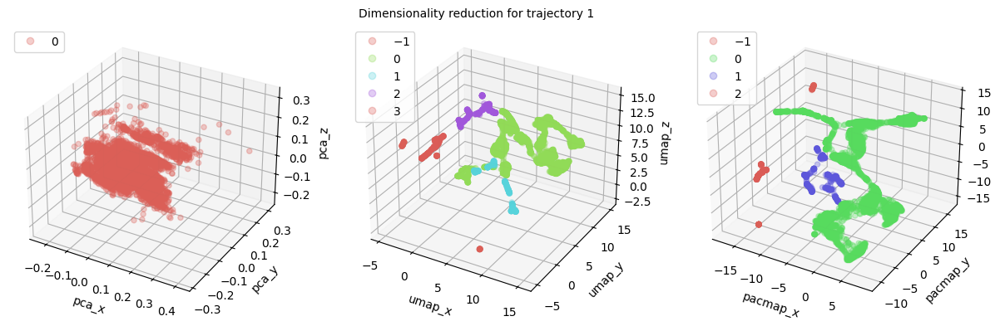

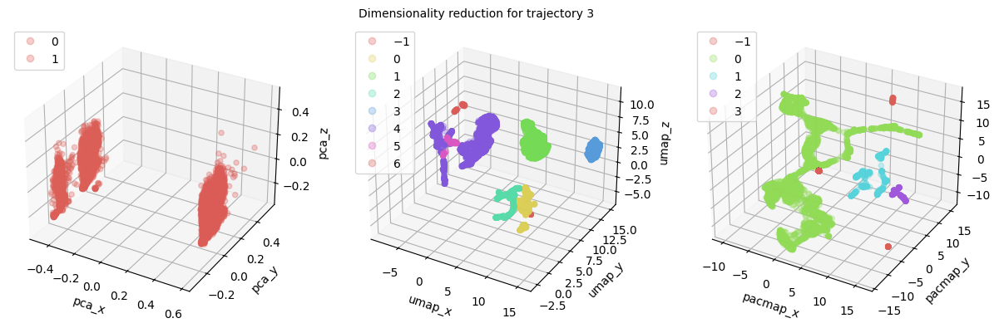

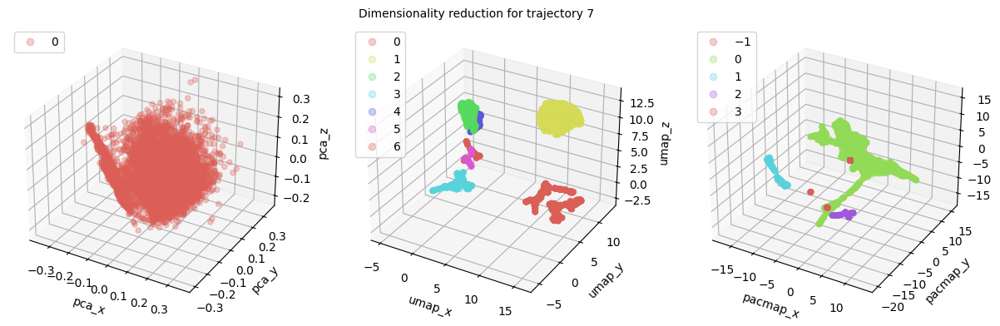

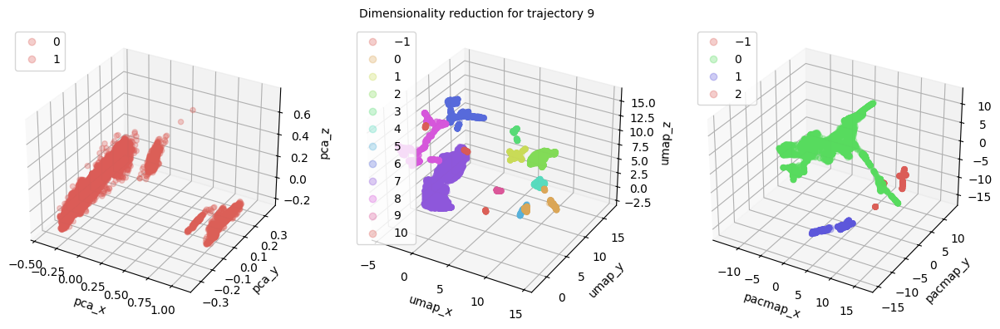

In [8]:
Clusters.subplotsScatter3D(4)

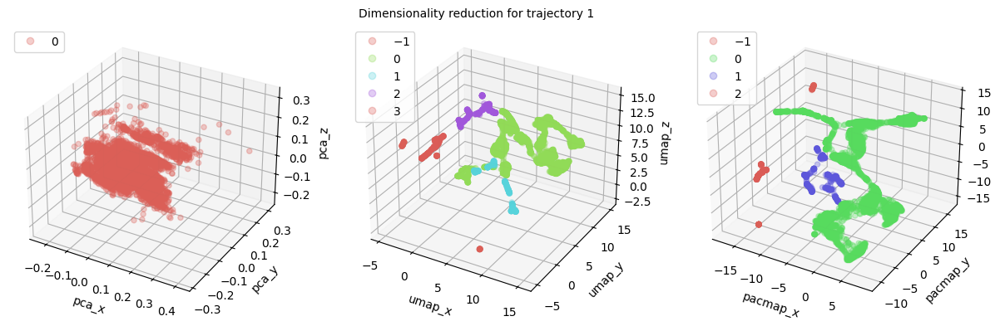

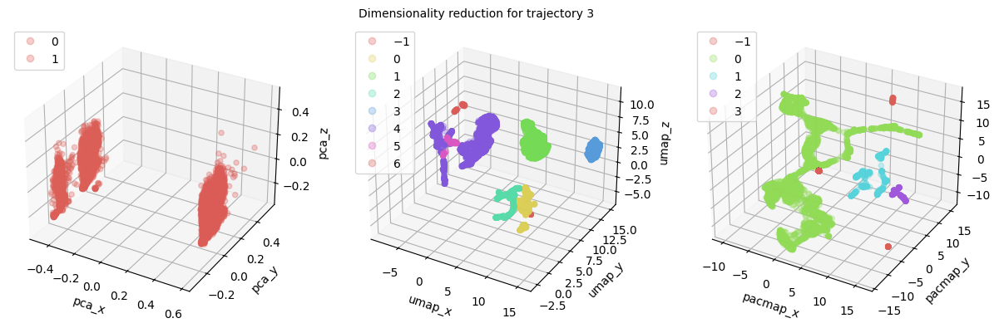

In [9]:
Clusters.subplotsScatter3D(2)

### Clusters in embedding space

In [10]:
Clusters.plotFigure('scatter3D', 
                    idxTrajectory=5, 
                    idxVariable=10, 
                    algorithm='pacmap')

### Time series colored by clusters

In [11]:
Clusters.plotFigure('lineplot', 
                    idxTrajectory=1, 
                    idxVariable=0, 
                    algorithm='pacmap')

# Clusters Comparison

In [12]:
dfSimilarclusters = Clusters.getSimilarClusters(algorithm='pacmap', 
                                                threshold=5)

In [13]:
idxGroupCluster = 1
scatterPlot3D(dfSimilarclusters[dfSimilarclusters['group']==idxGroupCluster], 
              x='pacmap_x', 
              y='pacmap_y', 
              z='pacmap_z', 
              color='label')

In [14]:
Clusters.trajectories

array(['1', '3', '7', '9', '11', '15', '17', '19', '21', '23', '25', '27',
       '29', '37', '39', '41', '45', '49', '51', '55', '61', '63', '65',
       '67', '71'], dtype=object)

In [15]:
# Clusters.plotFigure('lineplot', 
#                     idxTrajectory=2, 
#                     idxVariable=0, 
#                     algorithm='pacmap')

In [16]:
# Clusters.plotFigure('lineplot', 
#                     idxTrajectory=0, 
#                     idxVariable=0, 
#                     algorithm='pacmap')

# ------------------

NameError: name 'stop' is not defined

In [ ]:
def getCentroids(data, algorithm):
    embeddingData = data[[f'{algorithm}_x', f'{algorithm}_y', f'{algorithm}_z']]
    clusterLabels = data[f'cluster_{algorithm}'].astype('int')

    centroids = []
    for label in clusterLabels.unique():
        if label == -1: # Outliers are ignored
            continue

        cluster_points = embeddingData[clusterLabels== label]
        centroid       = np.mean(cluster_points, axis=0).values
        centroids.append(centroid)

    return embeddingData, clusterLabels, np.array(centroids)

In [ ]:
# def getSimilarClusters(idxTrajectory1, idxTrajectory2, algorithm, threshold):
#     dataTrajectory1 = Clusters.getTrajectory(idxTrajectory1)
#     embeddingData1, clusterLabels1, centroids1 = getCentroids(dataTrajectory1, algorithm)

#     dataTrajectory2 = Clusters.getTrajectory(idxTrajectory2)
#     embeddingData2, clusterLabels2, centroids2 = getCentroids(dataTrajectory2, algorithm)

#     distances = euclidean_distances(centroids1, centroids2)


#     similarClusters = {} 
#     for i, row in enumerate(distances):
#         for j, distance in enumerate(row):
#             if distance < threshold:
#                 cluster1, cluster2 = (i,j) 
#                 pointsCluster1 = embeddingData1[clusterLabels1 == cluster1].copy()
#                 pointsCluster2 = embeddingData2[clusterLabels2 == cluster2].copy() 

#                 pointsCluster1.loc[:,'label']=f'cluster: {cluster1}, trajectory:{4}'
#                 pointsCluster2.loc[:,'label']=f'cluster: {cluster2}, trajectory:{0}'
#                 dfResuts = pd.concat([pointsCluster1, pointsCluster2])
#                 dfResuts.loc[:, 'similar cluster'] = k
#                 similarClusters[(cluster1, cluster2)] = dfResuts
#     return similarClusters


In [ ]:
def getSimilarClusters(algorithm, threshold):
    L               = len(Clusters.clustersResults)
    iterator        = 0 
    similarClusters = pd.DataFrame()
    for idxTrajectory1 in range(L):
        for idxTrajectory2 in range(idxTrajectory1+1, L):
            dataTrajectory1                             = Clusters.getTrajectory(idxTrajectory1)
            trajectory1                                 = Clusters.trajectory
            embeddingData1, clusterLabels1, centroids1  = getCentroids(dataTrajectory1, algorithm)

            dataTrajectory2                             = Clusters.getTrajectory(idxTrajectory2)
            trajectory2                                 = Clusters.trajectory
            embeddingData2, clusterLabels2, centroids2  = getCentroids(dataTrajectory2, algorithm)

            distances                                   = euclidean_distances(centroids1, centroids2)

            for i, row in enumerate(distances):
                for j, distance in enumerate(row):
                    if distance < threshold:
                        cluster1, cluster2              = (i,j) 
                        pointsCluster1                  = embeddingData1[clusterLabels1 == cluster1].copy()
                        pointsCluster2                  = embeddingData2[clusterLabels2 == cluster2].copy() 
                        pointsCluster1.loc[:,'label']   = f'cluster: {cluster1}, trajectory:{trajectory1}'
                        pointsCluster2.loc[:,'label']   = f'cluster: {cluster2}, trajectory:{trajectory2}'
                        
                        dfResuts                        = pd.concat([pointsCluster1, pointsCluster2])
                        dfResuts.loc[:, 'group']        = iterator
                        similarClusters                 = pd.concat([similarClusters, dfResuts], ignore_index=True)
                        iterator+=1
    return similarClusters

In [ ]:
s=getSimilarClusters('pacmap', threshold=5)

In [ ]:
s['group'].unique()

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42], dtype=int64)

In [ ]:
# scatterPlot3D(s[s['group']==29], x='pacmap_x', y='pacmap_y', z='pacmap_z', color='label')

In [ ]:
data1 = Clusters.getTrajectory(2)
embeddingData1, clusterLabels1, centroids1 = getCentroids(data1, 'pacmap')

In [ ]:
data2 = Clusters.getTrajectory(0)
embeddingData2, clusterLabels2, centroids2 = getCentroids(data2, 'pacmap')

In [ ]:
distances = euclidean_distances(centroids1, centroids2)

In [ ]:
threshold = 5
similar_clusters = {} #[]
for i, row in enumerate(distances):
    for j, distance in enumerate(row):
        if distance < threshold:
            #cluster_pair = (i, j)
            cluster1_index, cluster2_index = (i,j) #cluster_pair
            cluster1_points = embeddingData1[clusterLabels1 == cluster1_index].copy()
            cluster2_points = embeddingData2[clusterLabels2 == cluster2_index].copy()

            cluster1_points.loc[:,'label']=f'cluster: {cluster1_index}, trajectory:{4}'
            cluster2_points.loc[:,'label']=f'cluster: {cluster2_index}, trajectory:{0}'
            similar_clusters[(cluster1_index, cluster2_index)] = pd.concat([cluster1_points, cluster2_points])

In [ ]:
similar_clusters[(0,0)]